# 07 — Probability and transition hypotheses

This notebook explains the transition layer rather than presenting another competing possession model. It separates:

`observations → scenario evidence → transition/no-switch hypotheses → interval resolver → optional Viterbi smoothing`

The immediate problem is not just defining more scenario labels. It is deciding when observations are trustworthy enough to change ownership, while preserving a no-switch or contested alternative during flight, poor touch, deflection, crowding, and occlusion.

## What kind of model is this?

The current pipeline is **not supervised learning**: the public ground truth is never used to fit weights, thresholds, transition costs, or labels. It is also not really unsupervised learning, because it does not discover parameters or latent states from an unlabeled dataset. The most accurate description is **knowledge-driven, rule-based probabilistic inference**.

The rules encode domain assumptions about control, flight, pressure, restarts, anchors, and missing-ball causes. Weighted scores and softmax turn those assumptions into comparable evidence values; interval logic and Viterbi perform model-based sequence inference. The word probability describes normalized uncertainty, not learned empirical frequency.

The taxonomy would change only when we fit parameters: calibration against reviewed labels would be supervised calibration; EM or another latent-state fitting procedure without labels would be unsupervised/semi-supervised learning; learned episode-duration distributions would make an HSMM data-driven rather than hand-specified. Until then, ground truth belongs to evaluation and error analysis only.

The physical observations behind this layer are shown in [03_scenario_engineering.ipynb](03_scenario_engineering.ipynb) and the restart/transition boundary study in [04_deadball_setpieces.ipynb](04_deadball_setpieces.ipynb). This notebook turns those observations into competing transition hypotheses rather than adding more final labels.

## Calibration and learning experiments

The reusable functions in [`possession_lab/calibration.py`](../possession_lab/calibration.py) make the next experiments explicit:

| Experiment | Mathematical construction | Label use | What it tests |
|---|---|---|---|
| MLE temperature scaling | choose `T > 0` that minimizes held-out multiclass negative log likelihood of the existing logits | reviewed labels on a calibration split only | whether the evidence vector is too sharp or too flat |
| Bayesian transition prior | Dirichlet posterior mean `(count_ij + alpha) / (row_count_i + K*alpha)` | trusted algorithmic anchors, not public labels | whether a smoothed transition matrix improves path decoding |
| EM HMM | forward-backward responsibilities, then update emission and transition parameters | no labels, or anchors as optional fixed constraints | whether latent states can be learned without copying the public labels |
| Data-driven HSMM | estimate state-duration distributions and decode segments | reviewed intervals or an external labelled corpus | whether possession/restart duration assumptions improve spell boundaries |

Haiqal did implement the second row as `BayesianAnchorHMM`: a Dirichlet-smoothed transition matrix estimated from algorithmic anchor states, followed by Viterbi. It is a useful reference, but it is not calibration of our `[P(H), P(A), P(D), P(X)]` vector. Our improvement is to apply the same prior to the transition ledger and explicit `NO_SWITCH`/`CONTESTED` hypotheses, then rank it beside the raw Haiqal baseline and the current scenario-aware resolver in 09.

Calibration must use disjoint contiguous windows: fit on a declared calibration window, report log loss/Brier/reliability on a holdout, and only then compare macro-F1, spell-F1, and transition F1@25. Otherwise the public score would measure label leakage rather than calibration.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
REPORTS = ROOT / 'evaluation' / 'reports'
RESULTS = ROOT / 'evaluation' / 'results'
print('project root:', ROOT)
print('reports:', REPORTS)
print('runner:', ROOT / 'possession_lab' / 'run_interpolated_flight_experiment.py')

project root: /Users/luke/Desktop/barca-hack-repo-staging
reports: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/reports
runner: /Users/luke/Desktop/barca-hack-repo-staging/possession_lab/run_interpolated_flight_experiment.py


## What a transition scenario asks us to observe

The scenario is a question about the evidence, not the final label. For example, `LONG_BALL` asks whether a flight ended in same-team control, an opposing control, or an unresolved contest. The transition layer therefore records the following observations before it selects an owner:

| Observation | What it can support | What it cannot prove alone |
|---|---|---|
| Ball acceleration, speed, direction and sharp change in direction | kick, reception, deflection, or continued flight | that the nearest player owns the ball |
| Distance margin, closing speed and predicted arrival time | which team could reach/control the ball first | that a player actually touched it |
| Local density, pressure and converging trajectories | contested, deflection, or dead-ball explanation | a definite turnover |
| Player/ball visibility and missing-ball cause | occlusion or geometric bridge uncertainty | possession during the gap |
| Post-touch ball persistence and controlled deceleration | stable reception/control anchor | the identity of a brief touch in isolation |
| Restart geometry and coordinated player movement | goal kick, corner, throw-in, free kick, kick-off, or dead ball | that a restart is taken merely because players are repositioning |

These observations create competing hypotheses: `SWITCH_TO_H`, `SWITCH_TO_A`, `NO_SWITCH`, and `CONTESTED/OCCLUDED`. The probability vector expresses their relative evidence; the interval resolver decides when the evidence is sufficient; Viterbi may then smooth the accepted path.

## 1. Observation probabilities

For every frame, the feature layer combines control, reception, flight, dead-ball, crowd, contest, missing-ball, distance-margin, and anchor evidence into `[P(H), P(A), P(D), P(X)]`. `X` means uncertain/abstain.

These values are currently a normalized rule-evidence vector produced with a softmax. They are **not calibrated probabilities**: `0.8` does not yet mean 80% empirical correctness. Their role is to keep evidence channels visible and give later decoders bounded emission-like inputs.

### The actual mathematics used

The current implementation is a transparent weighted-score model, not a learned generative HMM. Each evidence channel is first clipped or normalized to a comparable range. The possession-state logits are weighted sums, for example:

`z_H = 1.20 control_H + 0.85 reception_H + 0.35 post_H + 0.25 direction_H + 0.45 margin_H + 3.50 anchor_H`

with an analogous `z_A`; dead-ball and uncertainty receive their own logits. We convert logits to an evidence vector with the softmax:

`p_k = exp(z_k / T) / sum_j exp(z_j / T)`

where `k` is `H`, `A`, `D`, or `X`. The temperature is a numerical/evidence-sharpness parameter; because the weights were not fitted on reviewed labels, these are not calibrated probabilities.

For a possible switch, the trust score is another weighted sum. It combines opposite-anchor agreement, reception, post-contact persistence, proximity, closing/arrival geometry, contact physics, and flight support, then subtracts contest and occlusion penalties. The interval hypotheses are then normalized with another softmax over:

`[2 mean(trust_H), 2 mean(trust_A), no_switch_logit, contested_logit]`.

The resolver first finds an active interval from transition evidence, merges gaps of at most two frames, and aggregates evidence over that interval. It marks the interval `OCCLUDED` when at least half its frames are missing, `CONTESTED` when contest evidence is at least `0.6` or the H/A trust margin is below `0.08`, and otherwise creates a `SWITCH_CANDIDATE`. These are hypothesis-generation rules; deterministic anchors and the later interval resolver still control ownership.

In [2]:
probability_path = REPORTS / 'observation_probability_audit.csv'
columns = [
    'frame', 'scenario_context', 'scenario_state',
    'observation_probability_H', 'observation_probability_A',
    'observation_probability_D', 'observation_probability_X',
    'observation_probability_entropy', 'observation_probability_margin',
    'observation_probability_calibrated', 'observation_probability_model',
    'missing_ball_cause', 'scenario_crowd_score',
    'transition_hypothesis_state',
]
available = pd.read_csv(probability_path, nrows=0).columns
usecols = [column for column in columns if column in available]
probability = pd.read_csv(probability_path, usecols=usecols)
state_cols = [column for column in [
    'observation_probability_H', 'observation_probability_A',
    'observation_probability_D', 'observation_probability_X'
] if column in probability]
probability['probability_sum'] = probability[state_cols].sum(axis=1)
print('rows:', len(probability))
print('maximum normalization error:', float((probability['probability_sum'] - 1.0).abs().max()))
print('calibrated flag:', probability.get('observation_probability_calibrated', pd.Series(dtype=object)).unique())
probability[state_cols + ['observation_probability_entropy', 'observation_probability_margin']].describe()

rows: 199319
maximum normalization error: 4.440892098500626e-16
calibrated flag: [False]


,observation_probability_H,observation_probability_A,observation_probability_D,observation_probability_X,observation_probability_entropy,observation_probability_margin
count,199319.000000,199319.000000,199319.000000,199319.000000,199319.000000,199319.000000
mean,0.244629,0.196304,0.327523,0.231544,0.659922,0.476139
std,0.277544,0.241900,0.295385,0.171780,0.222770,0.217778
min,0.002388,0.001938,0.002047,0.002047,0.033082,0.000007
25%,0.020756,0.020756,0.109860,0.115134,0.499804,0.349835
50%,0.125851,0.109860,0.163470,0.191704,0.688760,0.495305
75%,0.409268,0.215413,0.708123,0.268411,0.845631,0.575079
max,0.993580,0.992909,0.822905,0.725469,0.998348,0.991440


## 2. Transition hypotheses are interval-level

The transition layer asks two separate questions:

1. Is a transition-like event happening?
2. If so, which team should own the next state?

Each interval keeps explicit alternatives: `H`, `A`, `NO_SWITCH`, and `CONTESTED`/`OCCLUDED`. A kick, direction change, receiver path, control signal, opposite anchor, crowd, deflection risk, or Kalman path can open an interval, but cannot own the next state by itself. This is how we avoid overwriting possession because of one noisy frame between two reliable anchors.

In [3]:
ledger = pd.read_csv(REPORTS / 'transition_hypothesis_ledger.csv')
ledger_cols = [column for column in ['p_H', 'p_A', 'p_no_switch', 'p_contested'] if column in ledger]
if ledger_cols:
    ledger['hypothesis_probability_sum'] = ledger[ledger_cols].sum(axis=1)
print('transition intervals:', len(ledger))
print(ledger.get('state', pd.Series(dtype=object)).value_counts(dropna=False))
if ledger_cols:
    print('maximum interval normalization error:', float((ledger['hypothesis_probability_sum'] - 1.0).abs().max()))
ledger.head(10)

transition intervals: 1306
state
NO_SWITCH           1098
SWITCH_CANDIDATE     198
CONTESTED             10
Name: count, dtype: int64
maximum interval normalization error: 2.220446049250313e-16


,interval_id,start_frame,end_frame,duration_frames,state,hypothesis_team,candidate_team,activity_max,activity_mean,p_H,...,closing_rate_max_mps,ball_speed_max_mps,kalman_path_available,kalman_reliable,kalman_uncertainty_max_m,missing_ball_cause,evidence_reason,conflict_reason,decoder_action,hypothesis_probability_sum
0,0,4198,4198,1,NO_SWITCH,NaN,A,0.226568,0.226568,0.121482,...,NaN,0.343908,False,False,0.139941,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
1,1,4203,4206,4,NO_SWITCH,NaN,H,0.228691,0.123683,0.135371,...,NaN,0.526587,False,False,0.252902,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
2,2,11359,11359,1,NO_SWITCH,NaN,A,0.055526,0.055526,0.102573,...,-0.539366,1.472524,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY,NONE,RETAIN_PRIOR_STATE,1.0
3,3,11393,11396,4,NO_SWITCH,NaN,A,0.176666,0.120059,0.115989,...,2.146664,0.476602,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
4,4,11608,11610,3,NO_SWITCH,NaN,H,0.087292,0.080835,0.066062,...,-0.367579,0.515097,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|CONTEST,COMPETING_PLAYERS|SAME_ANCHOR_CONTINUITY,RETAIN_PRIOR_STATE,1.0
5,5,11715,11716,2,NO_SWITCH,NaN,A,0.248294,0.198871,0.066762,...,1.779116,0.826542,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
6,6,11799,11801,3,NO_SWITCH,NaN,H,0.176113,0.147157,0.070677,...,6.576238,1.027654,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|CONTEST,COMPETING_PLAYERS,RETAIN_PRIOR_STATE,1.0
7,7,11943,11944,2,SWITCH_CANDIDATE,H,H,0.252395,0.194319,0.167640,...,5.640314,0.487505,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
8,8,11961,11963,3,NO_SWITCH,NaN,H,0.108596,0.101550,0.127192,...,3.242829,0.374861,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY,SAME_ANCHOR_CONTINUITY,RETAIN_PRIOR_STATE,1.0
9,9,11973,11973,1,NO_SWITCH,NaN,H,0.237048,0.237048,0.151639,...,3.655102,0.105341,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,SAME_ANCHOR_CONTINUITY,RETAIN_PRIOR_STATE,1.0


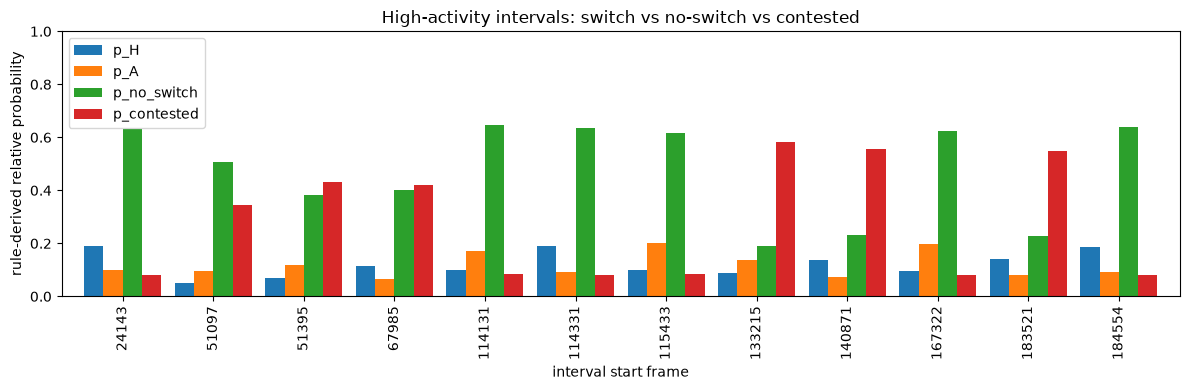

In [4]:
if not ledger.empty and ledger_cols:
    view = ledger.sort_values(['activity_max', 'start_frame'], ascending=[False, True]).head(12).sort_values('start_frame')
    ax = view.set_index('start_frame')[ledger_cols].plot.bar(
        figsize=(12, 4), ylim=(0, 1), width=0.85,
        title='High-activity intervals: switch vs no-switch vs contested'
    )
    ax.set_xlabel('interval start frame')
    ax.set_ylabel('rule-derived relative probability')
    plt.tight_layout()
    plt.show()

## 3. Resolver first; Viterbi and HSMM are later layers

The interval resolver is the first ownership decision layer. It requires bounded evidence such as opposing anchors, plausible reception/control, post-contact persistence, and compatible geometry. It can preserve the prior team or abstain.

Viterbi is an optional constrained path smoother after this layer. It may prefer a globally coherent path, but it must not invent evidence; hard anchors and explicit dead-ball constraints remain protected. Contested and occluded intervals make a switch more expensive.

HSMM is not the default yet because we do not have reliable duration distributions for live possession, dead-ball, flight, and contest episodes. Kalman is upstream geometry support only: it estimates a missing-ball path and uncertainty; it does not decide possession.

In [5]:
candidate_paths = {
    'resolver candidate': RESULTS / 'diagnostic_visible_ball_low_motion_dead_ball.csv',
    'transition-ledger Viterbi': RESULTS / 'baseline_transition_ledger_viterbi.csv',
    'probability-emission Viterbi': RESULTS / 'baseline_probability_transition_ledger_viterbi.csv',
    'duration-aware diagnostic': RESULTS / 'baseline_scenario_confidence_duration.csv',
}
for name, path in candidate_paths.items():
    print(f'{name}: {"available" if path.exists() else "not generated"} — {path.name}')
print('These are decoder variants for evaluation, not independent truth sources.')

resolver candidate: available — diagnostic_visible_ball_low_motion_dead_ball.csv
transition-ledger Viterbi: available — baseline_transition_ledger_viterbi.csv
probability-emission Viterbi: available — baseline_probability_transition_ledger_viterbi.csv
duration-aware diagnostic: available — baseline_scenario_confidence_duration.csv
These are decoder variants for evaluation, not independent truth sources.


## 4. What the probability experiment should solve next

The current model solves transparency and evidence combination. The next probability experiment should solve calibration:

1. reserve reviewed public transition intervals;
2. fit a small calibration layer to the evidence vector and transition outcome;
3. evaluate reliability diagrams and Brier score, not only F1;
4. keep deterministic anchors as constraints;
5. compare resolver-only, Viterbi, and probability-emission Viterbi on identical public windows.

Ground truth remains evaluation-only. The model learns from observable signals and uses forward/backward context only where the intended output permits that latency.